# Formative 2 - Multimodal Data Preprocessing
## Part 2: Facial Image Collection, Augmentation and Feature Extraction

**Project component:** input data for the face recognition model (the first security check).

### Objectives
1. Load and display the three required expressions (neutral, smiling, surprised) for every member.
2. Detect and crop the face so the model learns from the face, not the background.
3. Apply several augmentations per image to imitate real login conditions.
4. Extract colour histogram, LBP texture and HOG shape features, and save them to `datasets/image_features.csv`.

All processing code lives in [`src/image_pipeline.py`](../src/image_pipeline.py). The command-line demo reuses the same
functions on a new photo, so training and login always see identical preprocessing.

### Data layout
```
data/images/<member>/<member>_<expression>.<any image extension>
```
The folder name is the identity label. The expression is read from the file name, and common variants are accepted
(`Smile`, `smiling`, `SMILING`, `surprise`...).

### Supported formats
Photos can be JPEG, PNG, HEIC/HEIF (iPhone), WEBP, AVIF, BMP, TIFF or GIF. [`src/media_io.py`](../src/media_io.py)
opens each file by its content rather than its extension and applies the phone's EXIF rotation, so no manual conversion
is needed. Running `python -m src.media_io` from the repository root also converts any unusual format to JPEG and
renames files to the standard pattern. Photos left directly in `data/images/` (outside a member folder) and exact
duplicate files are reported with a warning instead of being silently mixed into the data.

## 1. Environment setup

This cell makes the notebook run anywhere without manual steps:

* **Locally** (Jupyter, VS Code, PyCharm on Windows, macOS or Linux) it finds the repository folder from wherever the
  notebook is opened.
* **On Google Colab, Kaggle or any other hosted notebook** it clones the repository first.
* It installs only the packages from `requirements.txt` that are missing, so an existing setup is never changed.

All file paths are relative to the repository, so nothing needs to be edited before running.

In [1]:
import importlib
import os
import subprocess
import sys
import warnings
from pathlib import Path

# The GitHub repository this notebook belongs to (only used when the notebook is opened on its own).
REPO_URL = os.environ.get("F2_REPO_URL", "https://github.com/mutaganzwa-desire/multimodal_data_preprocessing.git")
REQUIRED_FILES = ["app.py", "src/environment.py", "src/media_io.py", "src/verification.py"]


def missing_files(folder: Path) -> list:
    return [f for f in REQUIRED_FILES if not (folder / f).exists()]


def find_repo_root() -> Path:
    """Return the repository folder, cloning or updating it when needed.

    * Opened from inside a clone (Jupyter, VS Code or PyCharm on Windows, macOS or Linux): that clone is used.
    * Opened on its own (Google Colab, Kaggle, a downloaded .ipynb): the repository is cloned next to the
      notebook, and an older copy left there by a previous run is updated with `git pull`.
    """
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if not missing_files(folder):
            return folder
    target = Path.cwd() / "multimodal_data_preprocessing"
    if (target / ".git").exists():
        subprocess.run(["git", "-C", str(target), "pull", "-q", "--ff-only"], check=False)
    elif not target.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(target)], check=True)
    missing = missing_files(target)
    if missing:
        raise FileNotFoundError(
            f"The repository copy in {target} has no {', '.join(missing)}: it is older than this notebook. "
            "Push the latest commits to GitHub, delete that folder (on Colab: Runtime > Disconnect and delete "
            "runtime), and run this cell again."
        )
    return target


REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))
for name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[name]  # forget modules imported from another copy in an earlier run
importlib.invalidate_caches()

from src.environment import ensure_packages

ensure_packages()  # installs only the packages that are missing, then does nothing on later runs
warnings.filterwarnings("ignore", category=FutureWarning)
print("Repository folder:", REPO_ROOT.name)

All required packages are available.
Repository folder: multimodal_data_preprocessing


In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from skimage.feature import hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src import image_pipeline as ip
from src import media_io

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 80
# Photo grids are stored as JPEG so the saved notebook stays small.
%config InlineBackend.figure_formats = ["jpeg"]

## 2. Image inventory and completeness check

Every member must have one neutral, one smiling and one surprised photo with consistent naming.

In [3]:
images = ip.find_images()
members = sorted(images["member"].unique())

inventory = images.assign(
    file=images["path"].map(lambda p: p.name),
    real_format=images["path"].map(media_io.detect_format),
    width=images["path"].map(lambda p: ip.load_image(p).shape[1]),
    height=images["path"].map(lambda p: ip.load_image(p).shape[0]),
    size_kb=images["path"].map(lambda p: round(p.stat().st_size / 1024)),
).drop(columns="path")
display(inventory)

coverage = pd.crosstab(images["member"], images["expression"]).reindex(columns=list(ip.EXPRESSIONS), fill_value=0)
display(coverage)
missing = [(m, e) for m in coverage.index for e in coverage.columns if coverage.loc[m, e] == 0]
print("Missing expressions:", missing or "none, every member has all three")

,member,expression,file,real_format,width,height,size_kb
0,alain,neutral,alain_neutral.jpg,jpeg,1200,1600,500
1,alain,smiling,alain_smiling.jpg,jpeg,1200,1600,531
2,alain,surprised,alain_surprised.jpg,jpeg,1200,1600,485
3,arnold,neutral,arnold_neutral.jpeg,jpeg,2448,3264,1377
4,arnold,smiling,arnold_smiling.jpeg,jpeg,2448,3264,1356
5,arnold,surprised,arnold_surprised.jpeg,jpeg,2448,3264,1472
6,desire,neutral,desire_neutral.jpg,jpeg,1440,1426,157
7,desire,smiling,desire_smiling.jpg,jpeg,1440,3200,1171
8,desire,surprised,desire_surprised.jpg,jpeg,384,432,68
9,ivan,neutral,ivan_neutral.jpeg,jpeg,1080,918,75


expression,neutral,smiling,surprised
member,,,
alain,1,1,1
arnold,1,1,1
desire,1,1,1
ivan,1,1,1


Missing expressions: none, every member has all three


**Interpretation:** all four members (Alain, Arnold, Desire and Ivan) have the three expressions, and every file follows `<member>_<expression>.<ext>`. Arnold's photos arrived as `Neutral.jpeg`, `Smiling.jpeg` and `Surprised.jpeg` outside any member folder; they were moved to `data/images/arnold/` and renamed, since the folder name is the identity label. The `real_format` column confirms every file is a genuine JPEG, whatever its extension.

Resolution varies a lot: Arnold's are 2448 x 3264 phone shots, Alain's 1200 x 1600, Ivan's around 1000 x 1100, and Desire's range from 384 x 432 (the surprised photo, a picture of a printed photo) to 1440 x 3200. Every face is cropped and resized to 128 x 128 before feature extraction, so these differences do not change the feature vector, although the low-resolution photo carries less fine detail.

## 3. Sample pictures of each member

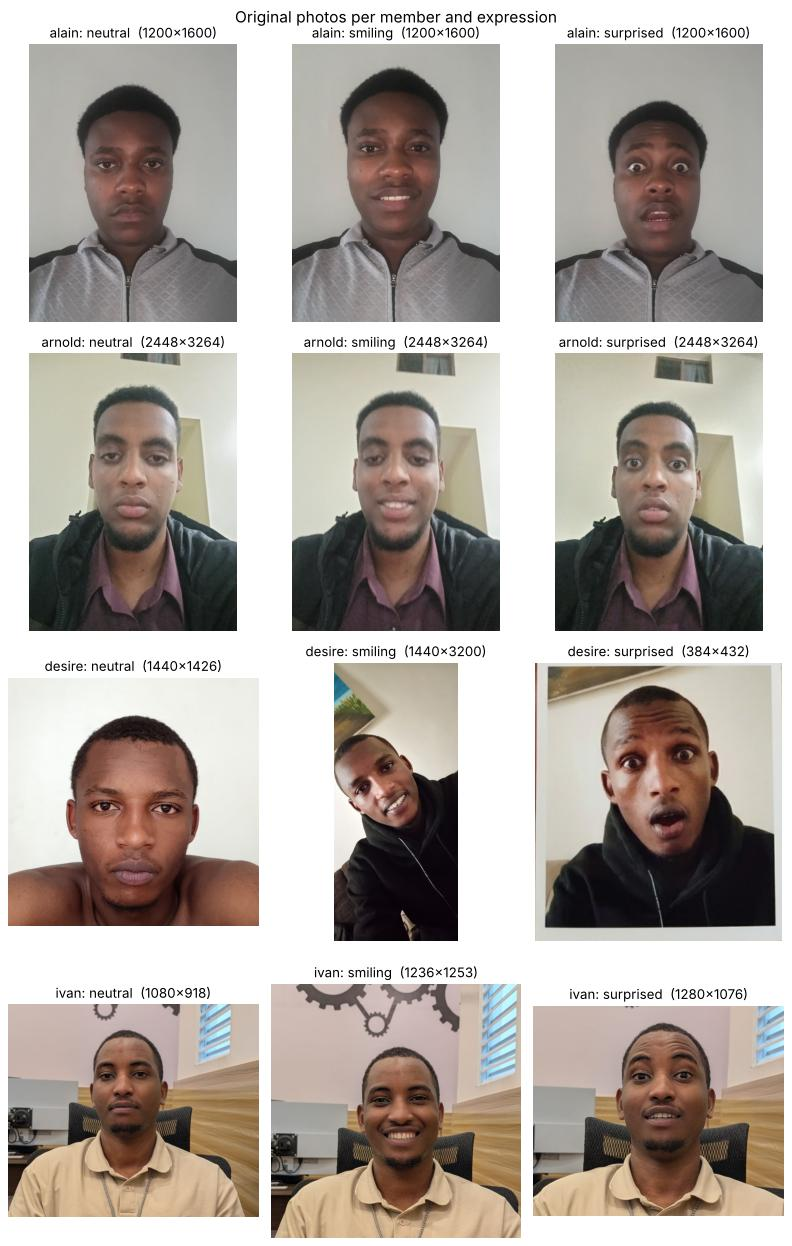

In [4]:
fig, axes = plt.subplots(len(members), 3, figsize=(10, 4 * len(members)))
for r, member in enumerate(members):
    for c, expression in enumerate(ip.EXPRESSIONS):
        ax = axes[r, c]
        match = images[(images["member"] == member) & (images["expression"] == expression)]
        if match.empty:
            ax.text(0.5, 0.5, "missing", ha="center", va="center")
        else:
            img = ip.load_image(match["path"].iloc[0])
            ax.imshow(img)
            ax.set_title(f"{member}: {expression}  ({img.shape[1]}x{img.shape[0]})")
        ax.axis("off")
fig.suptitle("Original photos per member and expression", fontsize=14)
fig.tight_layout()
plt.show()

**Interpretation:** the three expressions are easy to tell apart for every member: a relaxed closed mouth for neutral, visible teeth for smiling, and raised eyebrows with an open mouth for surprised. Backgrounds and lighting differ between members: a plain grey wall for Alain, a cream wall with a window for Arnold, an office with a chair and a wall decoration for Ivan, and a white wall, a room interior and a printed photo for Desire. Because each member's background is fairly constant across their own photos, a model fed the whole picture could learn the room instead of the person. That is why the face is cropped before features are extracted.

## 4. Face detection and cropping

The photos differ in framing, resolution and background, so features are taken from the face only:

1. Shrink the photo to a longest side of 800 px for speed.
2. Run OpenCV's Haar frontal face detector.
3. The detector only finds **upright** faces, so the photo is also tried rotated by 10, 20 and 30 degrees either way.
4. A candidate counts only if eyes are found in the upper part of the box. This rejects false hits such as a chin.
5. The candidate with the smallest rotation wins, so straight photos are never rotated.
6. Crop a square around the face with a 15% margin and resize it to 128 x 128 px.

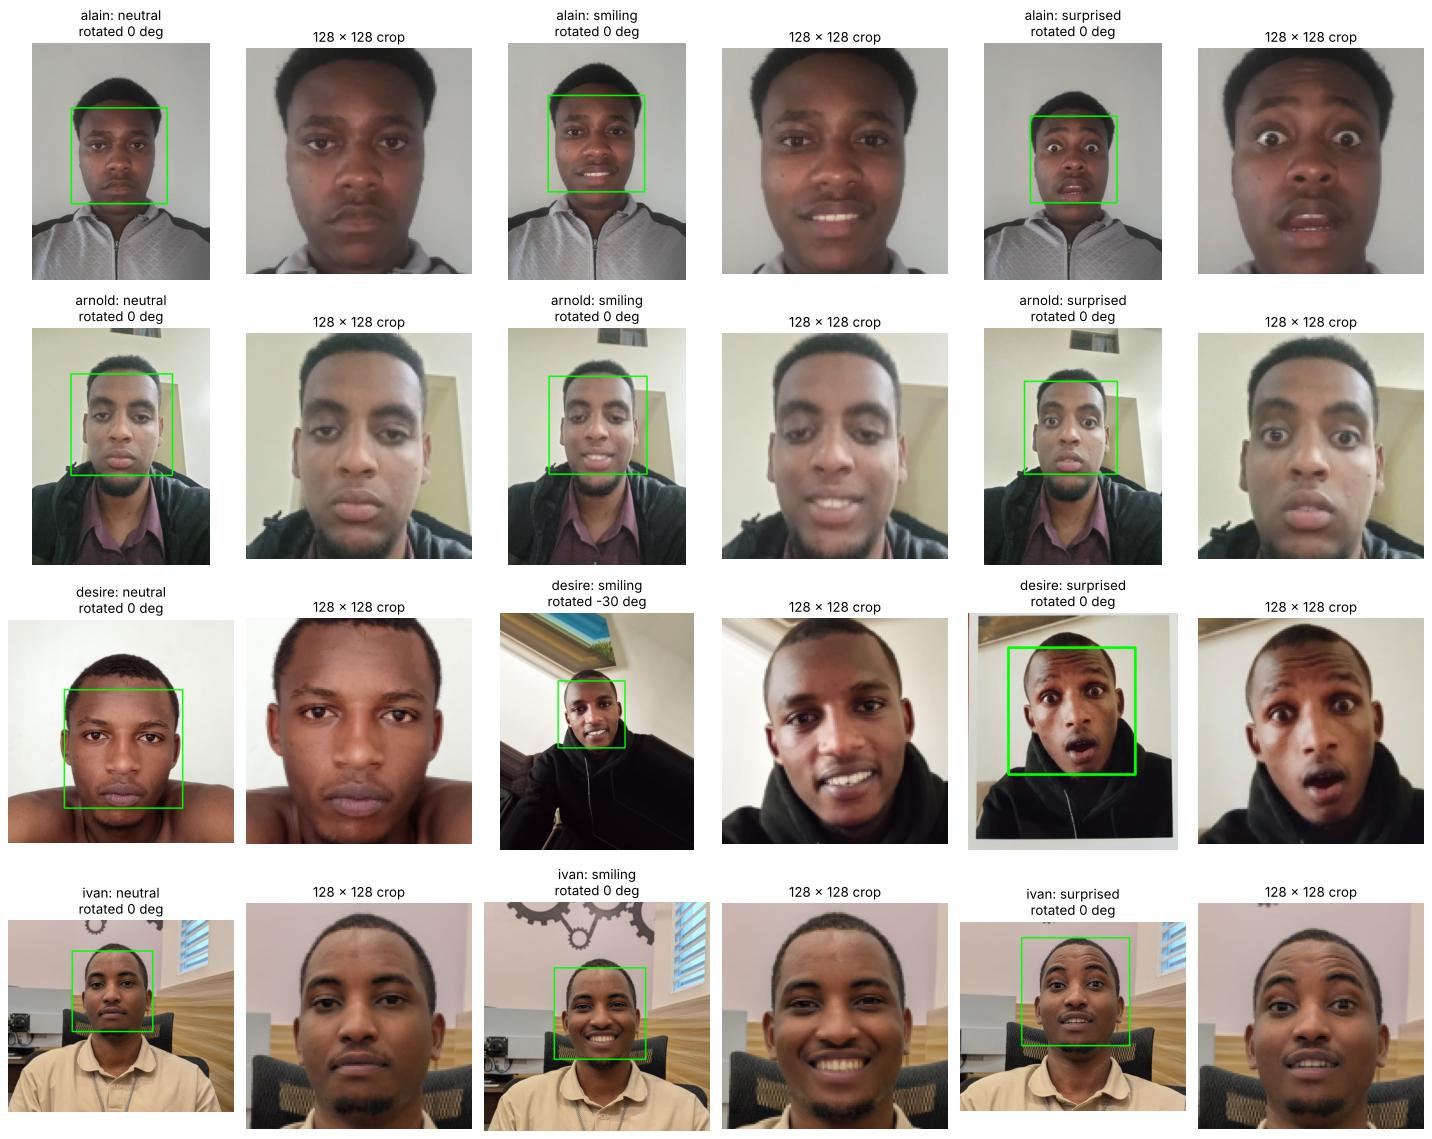

,photo,face_found,rotation_deg
0,alain_neutral.jpg,True,0
1,alain_smiling.jpg,True,0
2,alain_surprised.jpg,True,0
3,arnold_neutral.jpeg,True,0
4,arnold_smiling.jpeg,True,0
5,arnold_surprised.jpeg,True,0
6,desire_neutral.jpg,True,0
7,desire_smiling.jpg,True,-30
8,desire_surprised.jpg,True,0
9,ivan_neutral.jpeg,True,0


In [5]:
fig, axes = plt.subplots(len(members), 6, figsize=(18, 3.6 * len(members)))
detections = []
for r, member in enumerate(members):
    for c, expression in enumerate(ip.EXPRESSIONS):
        path = images[(images["member"] == member) & (images["expression"] == expression)]["path"].iloc[0]
        upright, box, angle = ip.locate_face(ip.load_image(path))
        shown = upright.copy()
        if box is not None:
            x, y, w, h = box
            cv2.rectangle(shown, (x, y), (x + w, y + h), (0, 255, 0), 4)
        axes[r, 2 * c].imshow(shown)
        axes[r, 2 * c].set_title(f"{member}: {expression}\nrotated {angle} deg")
        axes[r, 2 * c + 1].imshow(ip.crop_face(upright, box))
        axes[r, 2 * c + 1].set_title("128 x 128 crop")
        detections.append({"photo": path.name, "face_found": box is not None, "rotation_deg": angle})
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()
display(pd.DataFrame(detections))

**Interpretation:** a face was found in all twelve photos. Eleven were upright and used as they are. In `desire_smiling.jpg` the head is tilted by about 30 degrees, and the upright detector first latched onto the chin. The eye check rejected that box and the 30 degree rotation found the real face, which also straightens it. All crops are centred on the face at the same scale, so the features describe the person rather than the framing.

## 5. Augmentation

Each face crop gets **7 augmentations** plus the original, giving 8 versions per photo. Each one imitates a condition
the face model may meet at login time:

| Augmentation | Imitates |
|---|---|
| `rotate_+15`, `rotate_-15` | head tilted to either side |
| `flip_horizontal` | mirrored front-camera selfie |
| `grayscale` | black and white or colour-shifted camera |
| `brightness_up`, `brightness_down` | bright window or dim room |
| `gaussian_noise` | grainy low-light sensor |

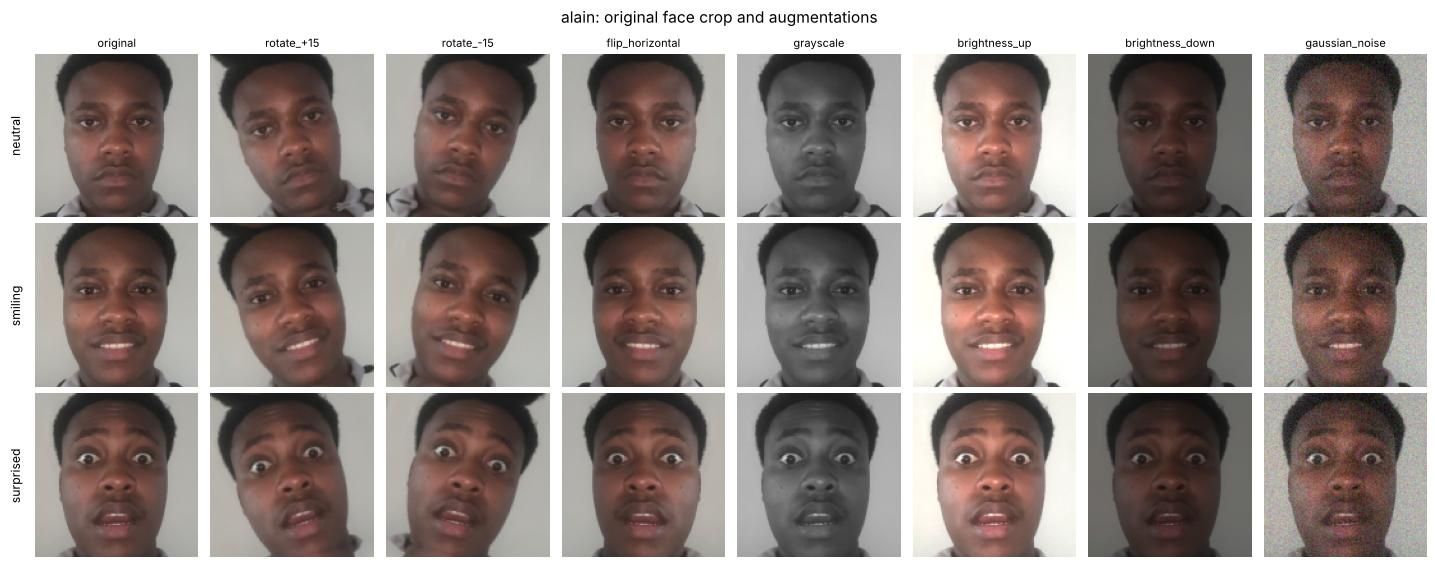

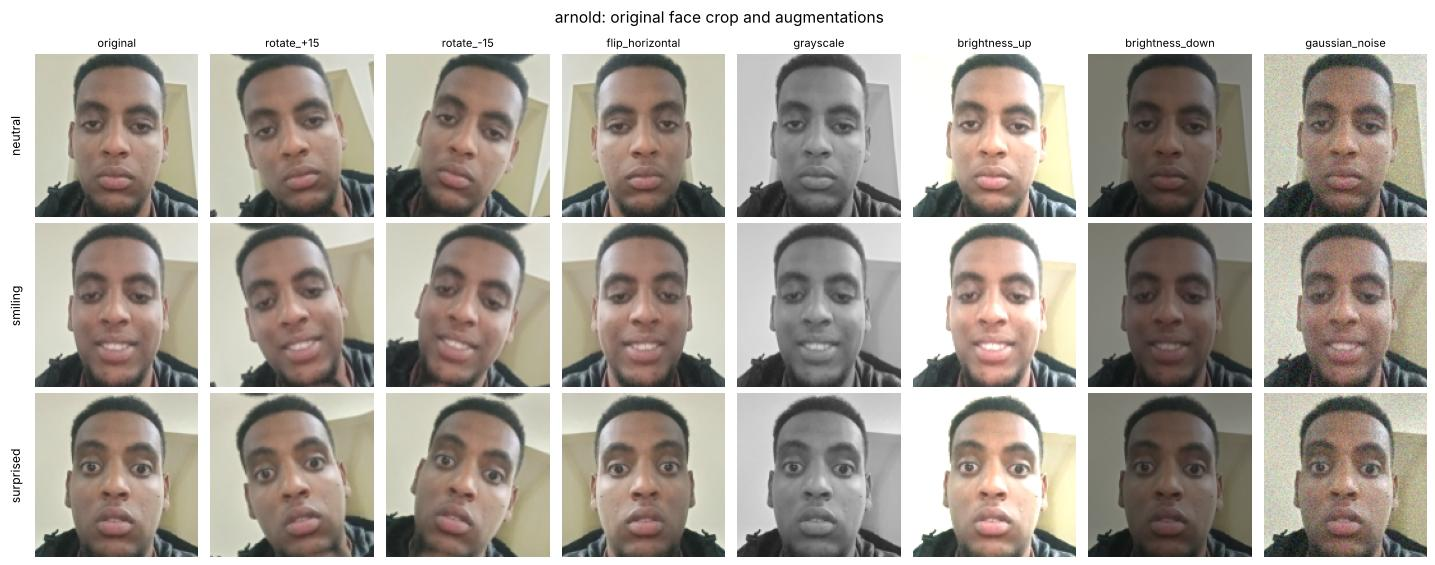

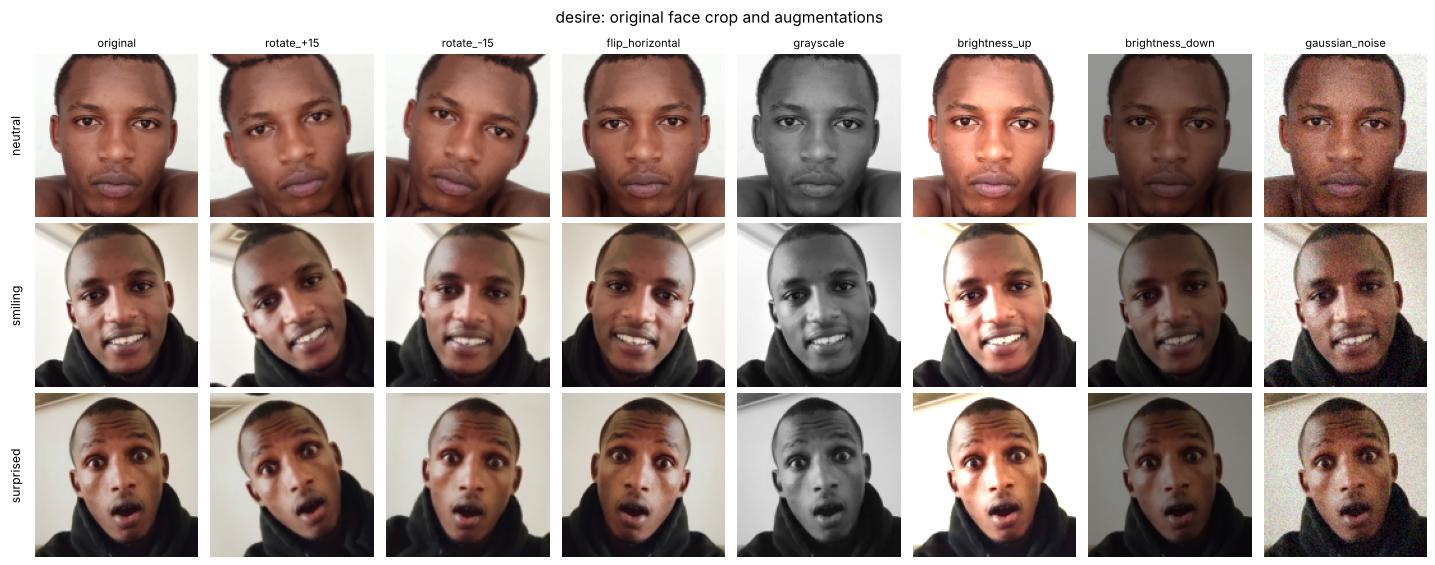

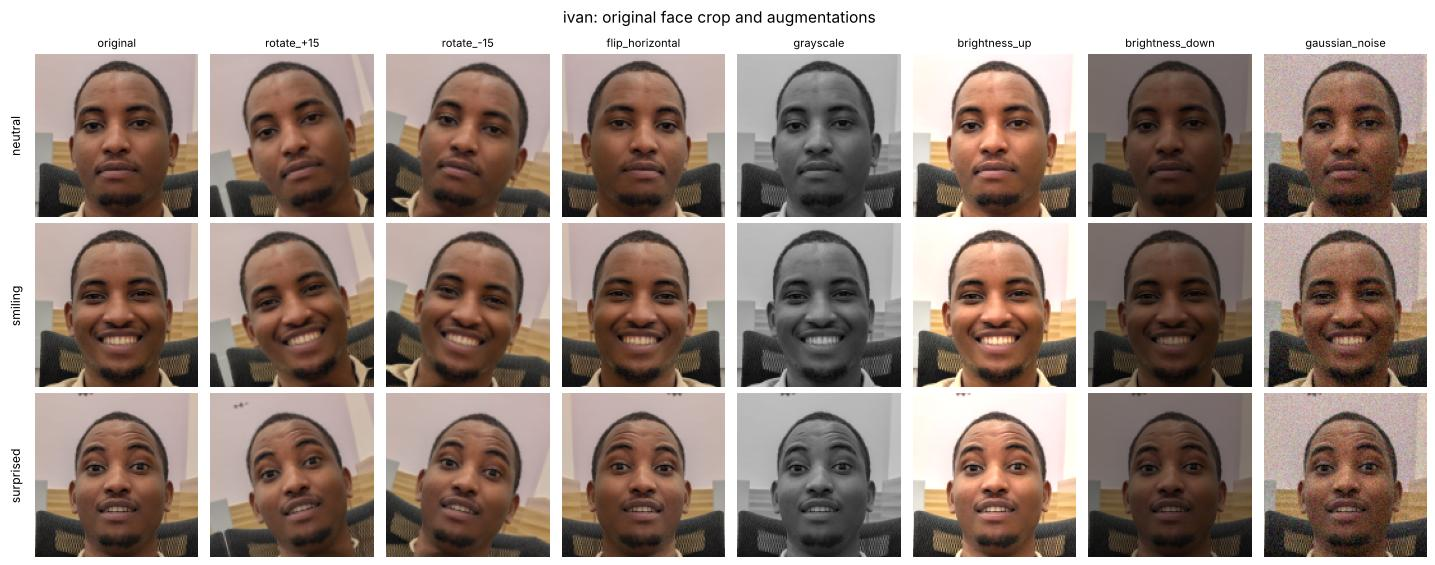

In [6]:
for member in members:
    fig, axes = plt.subplots(3, len(ip.AUGMENTATIONS), figsize=(18, 7.2))
    for r, expression in enumerate(ip.EXPRESSIONS):
        path = images[(images["member"] == member) & (images["expression"] == expression)]["path"].iloc[0]
        face, _ = ip.load_face(path)
        for c, (name, version) in enumerate(ip.augment(face).items()):
            axes[r, c].imshow(version)
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(name, fontsize=10)
        axes[r, 0].text(-10, 64, expression, rotation=90, va="center", ha="right", fontsize=11)
    fig.suptitle(f"{member}: original face crop and augmentations", fontsize=14)
    fig.tight_layout()
    plt.show()

**Interpretation:** every augmentation keeps the face recognisable, which is the goal: they add realistic variation without changing who is in the picture. The rotations reflect the border instead of adding black corners, so a model cannot learn to spot artificial edges. Grayscale removes colour completely, which forces the model to rely on texture (LBP) and shape (HOG) for those rows rather than on skin tone or lighting colour.

## 6. Feature extraction

Three complementary descriptors are computed on every face crop (532 values in total):

| Block | Columns | Size | What it captures |
|---|---|---|---|
| Colour histogram | `hist_0` to `hist_47` | 3 channels x 16 bins | skin tone and lighting |
| LBP texture | `lbp_0` to `lbp_159` | 4 x 4 grid x 10 uniform patterns | local skin and feature texture, robust to brightness |
| HOG shape | `hog_0` to `hog_323` | 3 x 3 blocks x 4 cells x 9 orientations | outline of eyes, nose, mouth and jaw |

The histograms are normalised, so photo resolution does not change the scale. The figure below shows what each
descriptor sees on one face.

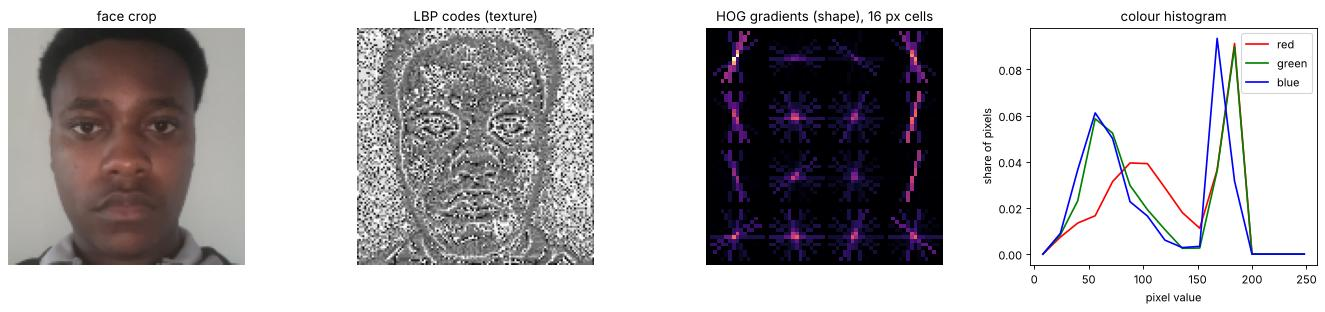

In [7]:
example_path = images[(images["member"] == members[0]) & (images["expression"] == "neutral")]["path"].iloc[0]
face, _ = ip.load_face(example_path)
gray = cv2.cvtColor(face, cv2.COLOR_RGB2GRAY)
_, hog_image = hog(cv2.resize(gray, (ip.HOG_SIZE, ip.HOG_SIZE)), orientations=9,
                   pixels_per_cell=(ip.HOG_CELL, ip.HOG_CELL), cells_per_block=(2, 2), visualize=True)
lbp_image = local_binary_pattern(gray, ip.LBP_POINTS, ip.LBP_RADIUS, method="uniform")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].imshow(face); axes[0].set_title("face crop")
axes[1].imshow(lbp_image, cmap="gray"); axes[1].set_title("LBP codes (texture)")
axes[2].imshow(hog_image, cmap="magma"); axes[2].set_title("HOG gradients (shape), 16 px cells")
for ax in axes[:3]:
    ax.axis("off")
hist = ip.color_histogram(face).reshape(3, -1)
centres = np.arange(ip.HIST_BINS) * (256 / ip.HIST_BINS) + 8
for channel, colour in zip(hist, ["red", "green", "blue"]):
    axes[3].plot(centres, channel, color=colour, label=colour)
axes[3].set_title("colour histogram"); axes[3].set_xlabel("pixel value"); axes[3].set_ylabel("share of pixels")
axes[3].legend()
fig.tight_layout()
plt.show()

**Interpretation:** the LBP map outlines the eyes, nostrils, mouth and hairline, while the flat wall turns into fine random texture. The HOG panel shows the dominant edge direction in each 16 px cell, the same coarse grid used for the features: it records the overall layout of the face rather than fine detail, which makes it tolerant to small shifts. The colour histogram has two peaks: the darker, wider one is skin and hair, and the bright narrow one is the grey wall left in the crop margin.

## 7. Build and save `image_features.csv`

One row per (photo, augmentation). Metadata columns come first, followed by the 532 feature columns.

In [8]:
features = ip.build_feature_table()
features.to_csv(ip.OUTPUT_CSV, index=False, float_format="%.6f")

feature_cols = ip.feature_columns(features)
metadata_cols = [c for c in features.columns if c not in feature_cols]
print(f"Saved {ip.OUTPUT_CSV.relative_to(REPO_ROOT)}: {features.shape[0]} rows, "
      f"{len(metadata_cols)} metadata columns, {len(feature_cols)} feature columns")
print("Feature blocks:", {b: sum(c.startswith(b + "_") for c in feature_cols) for b in ["hist", "lbp", "hog"]})
display(features[metadata_cols + feature_cols[:3] + ["lbp_0", "hog_0"]].head(10))

Saved datasets/image_features.csv: 96 rows, 7 metadata columns, 532 feature columns
Feature blocks: {'hist': 48, 'lbp': 160, 'hog': 324}


,image_id,member,expression,augmentation,source_image,face_detected,face_angle,hist_0,hist_1,hist_2,lbp_0,hog_0
0,alain_neutral__original,alain,neutral,original,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007365,0.013468,0.016602,0.275657
1,alain_neutral__rotate_+15,alain,neutral,rotate_+15,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007528,0.016886,0.011719,0.288805
2,alain_neutral__rotate_-15,alain,neutral,rotate_-15,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.010925,0.012919,0.016602,0.267734
3,alain_neutral__flip_horizontal,alain,neutral,flip_horizontal,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007365,0.013468,0.014648,0.297845
4,alain_neutral__grayscale,alain,neutral,grayscale,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007955,0.018270,0.016602,0.275657
5,alain_neutral__brightness_up,alain,neutral,brightness_up,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.000000,0.010254,0.020508,0.274834
6,alain_neutral__brightness_down,alain,neutral,brightness_down,data/images/alain/alain_neutral.jpg,True,0,0.000977,0.025411,0.042501,0.010742,0.273553
7,alain_neutral__gaussian_noise,alain,neutral,gaussian_noise,data/images/alain/alain_neutral.jpg,True,0,0.001404,0.007406,0.014242,0.127930,0.275777
8,alain_smiling__original,alain,smiling,original,data/images/alain/alain_smiling.jpg,True,0,0.000000,0.006734,0.012268,0.013672,0.289216
9,alain_smiling__rotate_+15,alain,smiling,rotate_+15,data/images/alain/alain_smiling.jpg,True,0,0.000000,0.006042,0.015279,0.008789,0.293537


In [9]:
# Validation of the saved file
saved = pd.read_csv(ip.OUTPUT_CSV)
checks = {
    "rows = photos x versions": len(saved) == len(images) * len(ip.AUGMENTATIONS),
    "no missing values": not saved.isna().any().any(),
    "unique image_id": saved["image_id"].is_unique,
    "every photo had a face detected": bool(saved["face_detected"].all()),
    "every member has 3 expressions": bool((saved.groupby("member")["expression"].nunique() == 3).all()),
}
display(pd.Series(checks, name="passed").to_frame())
display(pd.crosstab([saved["member"], saved["expression"]], saved["augmentation"]))

,passed
rows = photos x versions,True
no missing values,True
unique image_id,True
every photo had a face detected,True
every member has 3 expressions,True


augmentation       brightness_down  brightness_up  flip_horizontal  gaussian_noise  grayscale  original  rotate_+15  rotate_-15
member expression                                                                                                              
alain  neutral                   1              1                1               1          1         1           1           1
       smiling                   1              1                1               1          1         1           1           1
       surprised                 1              1                1               1          1         1           1           1
arnold neutral                   1              1                1               1          1         1           1           1
       smiling                   1              1                1               1          1         1           1           1
       surprised                 1              1                1               1          1         1           1           1
desire neutral                   1              1                1               1          1         1           1           1
       smiling                   1              1                1               1          1         1           1           1
       surprised                 1              1                1               1          1         1           1           1
ivan   neutral                   1              1                1               1          1         1           1           1
       smiling                   1              1                1               1          1         1           1           1
       surprised                 1              1                1               1          1         1           1           1

## 8. Do the features separate the members?

A quick look before any model is trained: standardise the 532 features and project them onto two principal components.
If each member forms their own region, the face recognition model has a usable signal.

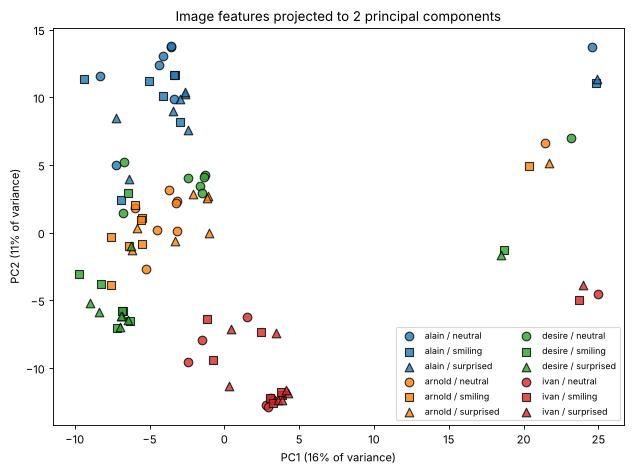

In [10]:
X = StandardScaler().fit_transform(saved[feature_cols])
pca = PCA(n_components=2, random_state=ip.SEED)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
markers = {"neutral": "o", "smiling": "s", "surprised": "^"}
colours = dict(zip(members, plt.cm.tab10.colors))
for (member, expression), idx in saved.groupby(["member", "expression"]).groups.items():
    ax.scatter(coords[idx, 0], coords[idx, 1], c=[colours[member]], marker=markers[expression],
               s=60, alpha=0.8, edgecolor="k", label=f"{member} / {expression}")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Image features projected to 2 principal components")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

**Identity signal check (not the final model).** Each photo is held out in turn with all 8 of its versions, and every
held-out version is labelled with the member of its nearest neighbour among the other photos. Holding out whole photos
matters: the versions of one photo are near copies, so a random row split would look far better than reality.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

blocks = {"all features": feature_cols,
          **{name: [c for c in feature_cols if c.startswith(name + "_")] for name in ["hist", "lbp", "hog"]}}
results = {}
for block, cols in blocks.items():
    correct = 0
    for photo in saved["source_image"].unique():
        train, test = saved[saved["source_image"] != photo], saved[saved["source_image"] == photo]
        scaler = StandardScaler().fit(train[cols])
        knn = KNeighborsClassifier(n_neighbors=1).fit(scaler.transform(train[cols]), train["member"])
        correct += (knn.predict(scaler.transform(test[cols])) == test["member"]).sum()
    results[block] = correct / len(saved)
display(pd.Series(results, name="leave-one-photo-out accuracy").round(2).to_frame())
print(f"Chance level with {len(members)} members: {1 / len(members):.2f}")

,leave-one-photo-out accuracy
all features,0.92
hist,0.93
lbp,0.82
hog,0.92


Chance level with 4 members: 0.25


**Interpretation:** the first two components explain 27% of the variance (16% + 11%), so most of the identity information lives in other directions, but the structure is already visible. Ivan's rows (red) form their own group at the bottom and Alain's (blue) at the top left, while Arnold (orange) and Desire (green) overlap in the middle; they are told apart by the remaining components. Each member's three expressions sit close together, which is what a face recognition model needs: a smile or surprise does not turn someone into another person.

The twelve points on the far right are the `gaussian_noise` versions of every photo. Pixel noise changes the LBP texture codes a lot, so these rows sit apart from everything else; they are a deliberately hard case that teaches the model to cope with grainy low-light photos.

The nearest-neighbour check confirms that the features carry identity: with all 532 features, 0.92 of held-out versions are matched to the right member, against 0.25 by chance with four members. The colour histogram (0.93) and HOG (0.92) are the strongest single blocks; LBP is weaker on its own (0.82) because of its sensitivity to noise, but it adds information when combined.

## 9. Summary and notes for the face recognition model

* **`datasets/image_features.csv`**: 96 rows (4 members x 3 expressions x 8 versions), 7 metadata columns and 532 feature columns (48 colour histogram, 160 LBP, 324 HOG). All validation checks pass.
* **Target column:** `member`. `expression` and `augmentation` are kept for analysis, not as model inputs.
* **Split by `source_image`, never by row.** The 8 versions of one photo are near copies; a random split would put copies of the same photo in both training and test sets and inflate the scores. The face model uses `GroupKFold` with `groups=source_image`.
* **Scaling:** standardise the features for Logistic Regression; Random Forest and XGBoost do not need it.
* **At login time** `ip.features_for_path(path)` turns a new photo of any format into the same 532 features. A classifier always picks one of the known members, so an unknown face is rejected when the model's confidence is below a threshold (see `Formative_2_Models_and_System_Demo.ipynb`).
* **Limitations:** one photo per expression per member is a very small dataset, and Desire's surprised photo is low resolution. More photos per member, in varied places and light, would make the face model more robust.